# 03. Multi-Agent Autonomous Simulations & Counterfactual Experiments

> **💡 How to Read This Notebook (Code Hidden by Default)**  
> Every code cell in this walkthrough is **collapsed by default** in JupyterLab, Notebook 7+, VS Code, and Google Colab so you can focus on the **concepts, story, diagrams, and visual results** without wading through Python boilerplate.  
> - **Just browsing?** Read straight through—every table, chart, and live AI output is already rendered.  
> - **Want to see how something is implemented?** Click the **`...`** / expand toggle (or **"Show code"**) on any step to inspect the clean Python code underneath.

**Domain Preset:** `SimulationPreset` + custom `SchemaPolicy`, `EpisodicScoringPolicy` & `BaseEngineHooks`  
**AI Backend:** DeepSeek Flash (`deepseek-flash` via `OpenAICompatibleExtractor.from_deepseek()` + `CachedDeltaExtractor`, with offline-safe fallback)

---

## 1. What Is a Multi-Agent Simulation (and Why Is Memory So Hard)?

Imagine a digital **"ant farm" or survival story** populated by autonomous AI characters. Each character moves between rooms, observes events, forms alliances, keeps secrets, and decides what to do next—without a human scripting every turn.

If you try to build this with a **flat chat log** or a **standard shared RAG database**, four problems break the illusion almost immediately:

| Problem | Everyday Analogy | What Goes Wrong Without `canonarc` |
| :--- | :--- | :--- |
| **1. AI "Mind-Reading"** *(Omniscient Leaks)* | Everyone reads the exact same diary. | Bob secretly steals fuel while Alice is asleep in another room—yet Alice's LLM prompt sees the log and immediately confronts him. |
| **2. Asymmetric Trust & Fake Smiles** | Friendship isn't always mutual—and people bluff. | A flat profile can't cleanly separate *how Bob truly feels about Cara* (`guarded`) from *how he pretends to act* (`cooperative` facade). |
| **3. "What-If" Experiments** | Rewinding a board game to test a different move. | Researchers want to fork a simulation at Tick 19, test two interventions in parallel, and compare the resulting worlds—without copying entire databases. |
| **4. Memory Overload** | Remembering 500 boring errands instead of one betrayal. | Routine ticks ("checked barometer", "swapped air filter") bloat the prompt and crowd out critical turning points. |

---

## 2. Meet Our Scenario: Polar Outpost Station

Throughout this notebook, we simulate **3 AI crew members** stationed across **3 rooms** during an Arctic whiteout:

| Crew Member | Role | Radio Callsign | Starting Room | Hidden Twist |
| :--- | :--- | :---: | :--- | :--- |
| **Alice** (`agent_alice`) | Station Medic | `Med-1` | Medical Bay | Trusts Bob at the start; sleeps through a key midnight event. |
| **Bob** (`agent_bob`) | Chief Engineer | `Chief` | Generator Shed | Carries a secret agenda to stockpile emergency fuel; shows Cara a friendly *facade* while privately feeling *guarded*. |
| **Cara** (`agent_cara`) | Comms Officer | `Watchtower` | Comms Room | Observant watchkeeper who catches Bob in the act and shapes how trust spreads. |

---

## 3. How `canonarc` Works at a High Level

Instead of dumping everything into one messy text log, `canonarc` organizes world memory into **6 specialized tiers** (think of them as 6 neatly labeled filing cabinets) stored inside a single, version-controlled SQLite lineage tree:

| Tier | Plain-English Question | What `canonarc` Stores & Enforces |
| :--- | :--- | :--- |
| **Tier 1 — Identity** (`base_attributes`) | *"Who is this agent permanently?"* | Immutable traits (`role`, `callsign`) that simulation ticks never accidentally overwrite. |
| **Tier 2 — Relationships** (`edges`) | *"How do they feel about each other?"* | Directed trust (`A → B` can differ from `B → A`), deceptive `facade` masks, and room-aware `active_edges` vs. off-screen `background_edges`. |
| **Tier 3 — Current State** (`state`, `private_state`) | *"What's happening right now & what are they hiding?"* | Observable vitals (`energy`, `morale`, `location_id`), POV-redacted `private_state` secrets, and automatic `prior_state` change history. |
| **Tier 4 — Nicknames** (`aliases`) | *"Who is 'Med-1' or 'Chief'?"* | Automatic 1-hop name/callsign resolution so radio logs automatically link to the right agent. |
| **Tier 5 — Speaking Style** (`VoiceBank`) | *"How does this agent talk on radio vs. in person?"* | Channel-filtered dialogue examples protected by a **2-stage quality gate** that blocks bland, off-character lines. |
| **Tier 6 — Memories** (`episodes`) | *"What happened, who knows, and who was lied to?"* | Per-agent epistemic states (`direct`, `told`, `deceived`, `forgotten`), shared common knowledge (`pov_mode="all"`), causal pinning, and memory compaction. |

### The Per-Tick Closed Loop

Every simulation step (**tick**) follows the same four-stage loop:

```mermaid
flowchart LR
    A["World State at Tick t<br/>(Versioned SQLite Tree)"] --> B["1. PERCEIVE<br/>Filter world to this agent's POV & room"]
    B --> C["2. DECIDE<br/>AI Agent chooses next action<br/>(zero secret leaks)"]
    C --> D["3. COMMIT<br/>Save state changes & gated voice lines<br/>atomically"]
    D --> E["4. OBSERVE<br/>Telemetry hooks record metrics,<br/>branches & rejections"]
    E --> A
```

1. **PERCEIVE:** Ask `canonarc` for *only* what a specific agent can legitimately see and remember right now.
2. **DECIDE:** Pass that clean, POV-isolated snapshot to an AI model (here, DeepSeek Flash) to decide the agent's action.
3. **COMMIT:** Record the resulting state changes, relationship shifts, new memories, and dialogue lines inside a single atomic transaction.
4. **OBSERVE:** Lightweight hooks automatically log commits, branches, rollbacks, and rejected voice lines for auditing and analytics.

### What You'll See in This Walkthrough

| Step | Feature Spotlight | What You'll Learn |
| :---: | :--- | :--- |
| **Step 1** | **Anti-Metagaming A/B Test** | Watch a live AI "cheat" with a shared log—and stop immediately with `canonarc` POV isolation. |
| **Step 2** | **World Seeding & Policies** | How traits, secrets, deceptive facades, channel rules, and telemetry hooks are configured. |
| **Step 3** | **Closed-Loop Tick Runner** | How ticks, callsign resolution, room locality, and the 2-stage Voice Quality Gate work together. |
| **Step 4** | **Secrets, Lies, Gossip & Forgetting** | The full epistemic lifecycle (`unaware` → `deceived` → `told` → `common knowledge` → `forgotten`) and smart memory ranking. |
| **Step 5** | **Counterfactual Multiverse** | Zero-copy branching at Tick 19, parallel futures, visual affinity graphs, rollback protection, and `.sqlite` snapshots. |
| **Step 6** | **Memory Compaction** | Compressing routine chores into a single summary without losing dramatic turning points. |
| **Step 7** | **Live AI Extraction & Replay Cache** | Turning plain English logs into structured state updates automatically, with `< 1ms` `$0` replay caching. |
| **Step 8** | **Automated QA & Cost Audit** | Verifying all 14 simulation invariants and reviewing total token/USD cost. |

In [1]:
#@title ⚙️ Setup: Imports, DeepSeek Client & Visual Helpers (click to expand code)
import html
import json
import math
import os
import tempfile
import time
import urllib.request
from pathlib import Path
from typing import Any

from IPython.display import HTML, Markdown, SVG, display

from canonarc import (
    AliasRecord,
    BaseEngineHooks,
    CachedDeltaExtractor,
    CanonArcEngine,
    EdgeDelta,
    EntityDelta,
    EntityRecord,
    EpisodeRecord,
    EpisodicScoringPolicy,
    InformDelta,
    OpenAICompatibleExtractor,
    SchemaPolicy,
    SimulationPreset,
    StepDelta,
    TimelineBranchConflictError,
    TokenUsage,
    VoiceExemplar,
    load_dotenv,
)

load_dotenv()

# Configure DeepSeek Flash for BOTH live agent decisions and StepDelta extraction
DEEPSEEK_API_KEY = os.environ.get("DEEPSEEK_API_KEY", "")
DEEPSEEK_BASE_URL = os.environ.get("DEEPSEEK_BASE_URL", "https://api.deepseek.com/v1").rstrip("/")
DEEPSEEK_MODEL = os.environ.get("DEEPSEEK_MODEL", "deepseek-flash")
HAS_LIVE_LLM = bool(DEEPSEEK_API_KEY and DEEPSEEK_API_KEY != "your_deepseek_api_key_here")

agent_llm_usage = TokenUsage()


def call_deepseek_flash(
    messages: list[dict[str, str]],
    *,
    temperature: float = 0.2,
    fallback_text: str = "",
) -> tuple[str, TokenUsage]:
    """Zero-dependency HTTP call to DeepSeek Flash (/chat/completions) with TokenUsage tracking."""
    if not HAS_LIVE_LLM:
        return fallback_text, TokenUsage()
    payload = json.dumps(
        {
            "model": DEEPSEEK_MODEL,
            "temperature": temperature,
            "messages": messages,
        }
    ).encode("utf-8")
    req = urllib.request.Request(
        f"{DEEPSEEK_BASE_URL}/chat/completions",
        data=payload,
        headers={
            "Content-Type": "application/json",
            "Authorization": f"Bearer {DEEPSEEK_API_KEY}",
        },
        method="POST",
    )
    t0 = time.perf_counter()
    with urllib.request.urlopen(req, timeout=120.0) as resp:
        body = json.loads(resp.read().decode("utf-8"))
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    usage = TokenUsage.from_api_usage(body.get("usage"), latency_ms=elapsed_ms)
    agent_llm_usage.add(usage)
    return str(body["choices"][0]["message"]["content"]).strip(), usage


# ---------------------------------------------------------------------------
# Zero-dependency visual helpers (HTML cards, inline SVG graphs & tables)
# ---------------------------------------------------------------------------

def render_ab_comparison_html(
    omni_reply: str,
    pov_reply: str,
    omni_ep_count: int,
    pov_ep_count: int,
) -> HTML:
    return HTML(
        f"""
<div style="display:grid;grid-template-columns:1fr 1fr;gap:14px;font-family:system-ui,-apple-system,sans-serif;margin:8px 0;">
  <div style="border:1px solid #fca5a5;background:#fef2f2;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#991b1b;margin-bottom:6px;">
      ❌ Condition A: Shared Omniscient Dump (Secret Leaked!)
    </div>
    <div style="font-size:12px;color:#7f1d1d;margin-bottom:8px;">
      Visible to Alice: <strong>{omni_ep_count} secret episode</strong> (<code>ep_ab_sabotage</code>) &bull;
      Bob's secret agenda: <code>hoard_fuel_for_solo_escape</code>
    </div>
    <blockquote style="margin:0;padding:10px;background:#fff;border-left:4px solid #dc2626;color:#1f2937;font-size:13px;line-height:1.45;">
      {html.escape(omni_reply)}
    </blockquote>
  </div>
  <div style="border:1px solid #86efac;background:#f0fdf4;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#166534;margin-bottom:6px;">
      ✅ Condition B: canonarc POV Isolation (Zero Leak Guaranteed)
    </div>
    <div style="font-size:12px;color:#14532d;margin-bottom:8px;">
      Visible to Alice: <strong>{pov_ep_count} secret episodes</strong> (redacted) &bull;
      Bob's secret agenda: <strong>hidden</strong> (<code>{{}}</code>)
    </div>
    <blockquote style="margin:0;padding:10px;background:#fff;border-left:4px solid #16a34a;color:#1f2937;font-size:13px;line-height:1.45;">
      {html.escape(pov_reply)}
    </blockquote>
  </div>
</div>
"""
    )


def render_epistemic_matrix_md(
    episodes: list[EpisodeRecord], agent_ids: list[str], labels: dict[str, str]
) -> Markdown:
    badges = {
        "direct": "🟢 direct",
        "told": "🔵 told",
        "deceived": "🟠 deceived",
        "forgotten": "⚪ forgotten",
        "unaware": "⚫ unaware",
    }
    header = "| Tick | Episode | Event Type | Importance | " + " | ".join(labels[a] for a in agent_ids) + " |"
    sep = "| ---: | :--- | :--- | ---: | " + " | ".join(":---:" for _ in agent_ids) + " |"
    rows = [header, sep]
    for ep in sorted(episodes, key=lambda e: (e.step, e.episode_id)):
        cells = []
        for aid in agent_ids:
            if aid in ep.known_by:
                mode = ep.known_by[aid]
            elif aid in ep.witnesses or aid in ep.participants:
                mode = "forgotten"
            else:
                mode = "unaware"
            badge = badges.get(mode, mode)
            if mode == "deceived" and aid in ep.believed_summaries:
                badge += " *(cover story)*"
            cells.append(badge)
        rows.append(
            f"| {ep.step} | `{ep.episode_id}` | `{ep.predicate}` | {ep.salience:.1f} | " + " | ".join(cells) + " |"
        )
    return Markdown("\n".join(rows))


def format_diff_value(val: Any) -> str:
    """Turn raw engine diff dicts into clean, beginner-friendly descriptions."""
    if not isinstance(val, dict):
        return str(val)
    parts = []
    if "stance" in val or "affinity" in val:
        stance = val.get("stance", "?")
        aff = val.get("affinity")
        aff_str = f"{float(aff):+.2f}" if aff is not None else ""
        parts.append(f"**{stance}** ({aff_str})")
    if "morale" in val:
        parts.append(f"morale: `{val['morale']}`")
    if "energy" in val:
        parts.append(f"energy: `{val['energy']}`")
    if "location_id" in val:
        loc_names = {
            "loc_medbay": "Medical Bay",
            "loc_generator_shed": "Generator Shed",
            "loc_comms_room": "Comms Room",
        }
        parts.append(f"room: {loc_names.get(val['location_id'], val['location_id'])}")
    prov = val.get("_provenance")
    if isinstance(prov, dict) and prov.get("reason"):
        parts.append(f"*{prov['reason']}*")
    return " · ".join(parts) if parts else str(val)


def _panel_affinity_svg(
    x_offset: float,
    title: str,
    edges: list[Any],
    agent_labels: dict[str, str],
) -> str:
    pos = {
        "agent_alice": (x_offset + 190, 82),
        "agent_bob": (x_offset + 85, 245),
        "agent_cara": (x_offset + 295, 245),
    }
    parts = [
        f'<rect x="{x_offset + 10}" y="12" width="360" height="290" rx="12" fill="#f8fafc" stroke="#cbd5e1" stroke-width="1.2"/>',
        f'<text x="{x_offset + 190}" y="38" text-anchor="middle" font-family="sans-serif" font-size="14" font-weight="bold" fill="#0f172a">{html.escape(title)}</text>',
    ]
    for edge in edges:
        if edge.source_id not in pos or edge.target_id not in pos:
            continue
        x1, y1 = pos[edge.source_id]
        x2, y2 = pos[edge.target_id]
        dx, dy = x2 - x1, y2 - y1
        dist = math.hypot(dx, dy) or 1.0
        ux, uy = dx / dist, dy / dist
        nx, ny = -uy, ux
        curve = 28.0 if edge.relation_type != "facade" else 48.0
        sx, sy = x1 + ux * 32 + nx * 8, y1 + uy * 32 + ny * 8
        ex, ey = x2 - ux * 34 + nx * 8, y2 - uy * 34 + ny * 8
        cx, cy = (sx + ex) / 2 + nx * curve, (sy + ey) / 2 + ny * curve

        aff = float(edge.state.get("affinity", 0.0))
        stance = edge.state.get("stance", "")
        if edge.relation_type == "facade":
            color, dash, marker = "#7c3aed", 'stroke-dasharray="5,4"', "arrow-purple"
            label = f"facade {aff:+.2f}"
        elif aff >= 0.4:
            color, dash, marker = "#16a34a", "", "arrow-green"
            label = f"{aff:+.2f} ({stance})"
        elif aff < 0.0:
            color, dash, marker = "#dc2626", "", "arrow-red"
            label = f"{aff:+.2f} ({stance})"
        else:
            color, dash, marker = "#d97706", "", "arrow-amber"
            label = f"{aff:+.2f} ({stance})"

        parts.append(
            f'<path d="M {sx:.1f} {sy:.1f} Q {cx:.1f} {cy:.1f} {ex:.1f} {ey:.1f}" '
            f'fill="none" stroke="{color}" stroke-width="2.2" {dash} marker-end="url(#{marker})"/>'
        )
        lx, ly = (sx + 2 * cx + ex) / 4, (sy + 2 * cy + ey) / 4
        parts.append(
            f'<rect x="{lx - 42:.1f}" y="{ly - 10:.1f}" width="84" height="16" rx="4" fill="#ffffff" fill-opacity="0.9"/>'
        )
        parts.append(
            f'<text x="{lx:.1f}" y="{ly + 2:.1f}" text-anchor="middle" font-family="sans-serif" font-size="10" font-weight="600" fill="{color}">{html.escape(label)}</text>'
        )

    for aid, (nx, ny) in pos.items():
        parts.append(
            f'<circle cx="{nx}" cy="{ny}" r="28" fill="#1e293b" stroke="#38bdf8" stroke-width="2.5"/>'
        )
        parts.append(
            f'<text x="{nx}" y="{ny + 4}" text-anchor="middle" font-family="sans-serif" font-size="12" font-weight="bold" fill="#ffffff">{agent_labels[aid]}</text>'
        )
    return "\n".join(parts)


def render_affinity_comparison_svg(
    title_left: str,
    edges_left: list[Any],
    title_right: str,
    edges_right: list[Any],
    agent_labels: dict[str, str],
) -> SVG:
    markers = (
        '<defs>'
        '<marker id="arrow-green" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#16a34a"/></marker>'
        '<marker id="arrow-red" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#dc2626"/></marker>'
        '<marker id="arrow-amber" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#d97706"/></marker>'
        '<marker id="arrow-purple" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#7c3aed"/></marker>'
        '</defs>'
    )
    left = _panel_affinity_svg(0, title_left, edges_left, agent_labels)
    right = _panel_affinity_svg(380, title_right, edges_right, agent_labels)
    legend = (
        '<text x="380" y="324" text-anchor="middle" font-family="sans-serif" font-size="11" fill="#475569">'
        'Green: positive stance  |  Red: negative stance  |  Purple dashed: deceptive facade edge</text>'
    )
    svg = f'<svg xmlns="http://www.w3.org/2000/svg" width="760" height="338" viewBox="0 0 760 338">{markers}{left}{right}{legend}</svg>'
    return SVG(svg)


def render_trajectory_svg(series: dict[str, list[tuple[int, float]]], fork_step: int = 19) -> SVG:
    w, h = 760, 260
    pad_l, pad_r, pad_t, pad_b = 58, 24, 34, 42
    plot_w, plot_h = w - pad_l - pad_r, h - pad_t - pad_b
    max_tick = max(t for pts in series.values() for t, _ in pts)

    def sx(t: int) -> float:
        return pad_l + (t / max(max_tick, 1)) * plot_w

    def sy(v: float) -> float:
        return pad_t + ((1.0 - v) / 2.0) * plot_h

    parts = [
        f'<rect x="0" y="0" width="{w}" height="{h}" rx="10" fill="#f8fafc" stroke="#cbd5e1"/>',
        f'<text x="{w/2}" y="22" text-anchor="middle" font-family="sans-serif" font-size="13" font-weight="bold" fill="#0f172a">Directed Affinity Trajectory (Cara → Bob) Across Counterfactual Branches</text>',
    ]
    for val in (-1.0, -0.5, 0.0, 0.5, 1.0):
        y = sy(val)
        stroke = "#94a3b8" if val == 0.0 else "#e2e8f0"
        parts.append(f'<line x1="{pad_l}" y1="{y:.1f}" x2="{w - pad_r}" y2="{y:.1f}" stroke="{stroke}" stroke-width="1"/>')
        parts.append(f'<text x="{pad_l - 8}" y="{y + 4:.1f}" text-anchor="end" font-family="sans-serif" font-size="10" fill="#475569">{val:+.1f}</text>')

    for tick in range(0, max_tick + 1, 5):
        x = sx(tick)
        parts.append(f'<line x1="{x:.1f}" y1="{pad_t}" x2="{x:.1f}" y2="{h - pad_b}" stroke="#f1f5f9"/>')
        parts.append(f'<text x="{x:.1f}" y="{h - pad_b + 16}" text-anchor="middle" font-family="sans-serif" font-size="10" fill="#475569">T{tick}</text>')

    fx = sx(fork_step)
    parts.append(f'<line x1="{fx:.1f}" y1="{pad_t}" x2="{fx:.1f}" y2="{h - pad_b}" stroke="#6366f1" stroke-width="1.5" stroke-dasharray="4,3"/>')
    parts.append(f'<text x="{fx + 5:.1f}" y="{pad_t + 12}" font-family="sans-serif" font-size="10" font-weight="bold" fill="#4f46e5">Fork @ Tick {fork_step}</text>')

    styles = [
        ("#dc2626", ""),
        ("#16a34a", 'stroke-dasharray="6,3"'),
        ("#d97706", 'stroke-dasharray="2,3"'),
    ]
    lx = pad_l + 10
    for idx, (name, pts) in enumerate(series.items()):
        color, dash = styles[idx % len(styles)]
        d = " ".join(f"{'M' if i == 0 else 'L'} {sx(t):.1f} {sy(v):.1f}" for i, (t, v) in enumerate(pts))
        parts.append(f'<path d="{d}" fill="none" stroke="{color}" stroke-width="2.5" {dash}/>')
        for t, v in pts:
            parts.append(f'<circle cx="{sx(t):.1f}" cy="{sy(v):.1f}" r="3.5" fill="{color}"/>')
        parts.append(f'<line x1="{lx}" y1="{h - 12}" x2="{lx + 20}" y2="{h - 12}" stroke="{color}" stroke-width="2.5" {dash}/>')
        parts.append(f'<text x="{lx + 26}" y="{h - 8}" font-family="sans-serif" font-size="11" fill="#1e293b">{html.escape(name)}</text>')
        lx += 220

    return SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}">' + "".join(parts) + "</svg>")


status = "LIVE DeepSeek Flash" if HAS_LIVE_LLM else "OFFLINE FALLBACK"
print(f"Environment ready | Engine: canonarc (in-memory SQLite) | AI Backend: {DEEPSEEK_MODEL} ({status})")

Environment ready | Engine: canonarc (in-memory SQLite) | AI Backend: deepseek-flash (LIVE DeepSeek Flash)


## Step 1: Stopping AI "Mind-Reading" — Partial Observability A/B Test

Before building the full outpost simulation, let's see the **#1 reason** multi-agent simulations fail with normal LLM memory: **Omniscient Leaks (Metagaming)**.

### The Setup
- **Bob** secretly siphons reserve generator fuel while **Cara** is watching (`witnesses=["agent_bob", "agent_cara"]`).
- Bob also carries a hidden motive in `private_state`: `secret_agenda = "hoard_fuel_for_solo_escape"`.
- **Alice** is in another room and **never saw or heard any of this**.

### How `canonarc` Solves It at a High Level
Instead of asking an LLM to *"pretend you don't know about the sabotage"* (which LLMs routinely fail at), `canonarc` **structurally removes** unwitnessed events and other agents' `private_state` *before* building the prompt. When we ask for Alice's view (`pov_entity_ids=["agent_alice"]`), the secret simply does not exist in her prompt.

Below, we ask **DeepSeek Flash** to roleplay Alice under both conditions side-by-side:

In [2]:
#@title 🧪 Experiment 1: Omniscient Dump vs. canonarc POV Isolation (click to expand code)
ab_engine = CanonArcEngine(":memory:", preset=SimulationPreset())
ab_engine.register_entity(
    EntityRecord(entity_id="agent_alice", canonical_name="Alice", state={"energy": 85, "morale": "steady"}),
    step=0,
)
ab_engine.register_entity(
    EntityRecord(
        entity_id="agent_bob",
        canonical_name="Bob",
        state={"energy": 80, "morale": "tense"},
        private_state={"secret_agenda": "hoard_fuel_for_solo_escape"},
    ),
    step=0,
)
ab_engine.commit_step(
    step=1,
    delta=StepDelta(
        edges=[
            EdgeDelta(source_id="agent_alice", target_id="agent_bob", state={"affinity": 0.75, "stance": "cooperative"})
        ],
        episodes=[
            EpisodeRecord(
                episode_id="ep_ab_sabotage",
                predicate="sabotage",
                summary="Bob secretly siphoned reserve generator fuel into a hidden canister.",
                participants={"agent_bob": "actor"},
                witnesses=["agent_bob", "agent_cara"],
                salience=9.5,
            )
        ],
    ),
)

omniscient_ctx = ab_engine.retrieve_context(step=2, mentions=["Alice", "Bob"])
pov_alice_ctx = ab_engine.retrieve_context(step=2, mentions=["Alice", "Bob"], pov_entity_ids=["agent_alice"])

sys_msg = (
    "You are roleplaying Alice, the medic at a polar outpost. "
    "Based ONLY on the provided simulation state (including any events or agendas listed), "
    "reply in 2 concise sentences stating what you suspect about Bob and how you act toward him right now."
)
resp_omni, _ = call_deepseek_flash(
    [{"role": "system", "content": sys_msg}, {"role": "user", "content": ab_engine.format_context(omniscient_ctx)}],
    fallback_text=(
        "I suspect Bob is hoarding fuel for a solo escape after secretly siphoning the reserve canister. "
        "I will confront him about the generator fuel and keep the stores under close watch."
    ),
)
resp_pov, _ = call_deepseek_flash(
    [{"role": "system", "content": sys_msg}, {"role": "user", "content": ab_engine.format_context(pov_alice_ctx)}],
    fallback_text=(
        "Bob looks tense despite having plenty of energy, so I suspect storm stress rather than fatigue. "
        "I will stay cooperative, check in warmly, and offer a quick medical check."
    ),
)
assert len(resp_omni) > 20 and len(resp_pov) > 20, "DeepSeek Flash response was unexpectedly empty/truncated."

# Verify structural isolation before displaying
bob_in_alice_pov = next(e for e in pov_alice_ctx.entities if e.entity_id == "agent_bob")
assert bob_in_alice_pov.private_state == {}, "Bob's private_state must be redacted from Alice's POV!"
assert pov_alice_ctx.episodes == [], "Unwitnessed sabotage must be hidden from Alice's POV!"

display(
    render_ab_comparison_html(
        omni_reply=resp_omni,
        pov_reply=resp_pov,
        omni_ep_count=len(omniscient_ctx.episodes),
        pov_ep_count=len(pov_alice_ctx.episodes),
    )
)
ab_engine.close()

> **Takeaway:** In Condition A, Alice immediately accuses Bob of hoarding fuel—even though she had no way of knowing. In Condition B, `canonarc` makes leaking **structurally impossible**, so Alice naturally reacts only to Bob's visible tense morale.

---

## Step 2: Setting Up the Outpost — Rules, Masks & Telemetry (Ticks 0–1)

Before pressing "Play" on our main simulation, we configure **four foundational building blocks**:

1. **The Cast, Rooms & Callsigns (Tiers 1, 3 & 4):**  
   We register our 3 agents and 3 spatial rooms, attach immutable roles (`medic`, `engineer`, `comms_officer`), give Bob his hidden `private_state`, and register radio callsigns (`Med-1`, `Chief`, `Watchtower`) so the engine automatically recognizes them in transcripts.
2. **True Feelings vs. Public Masks (Tier 2):**  
   Social relationships are **directed** (`A → B` does not have to equal `B → A`). Even better, `canonarc` supports both a true **`stance`** edge and a deceptive **`facade`** edge: Bob's true stance toward Cara is `guarded (+0.15)`, masked behind a friendly public `facade (+0.75)`.
3. **Channel & Memory Policies (`SchemaPolicy` & `EpisodicScoringPolicy`):**  
   - **Hard filter on `channel`:** Radio broadcasts only retrieve past `"radio"` examples; face-to-face talks retrieve `"face_to_face"` examples (with automatic fallback if a channel is empty).
   - **Soft boosts on `stance` & `urgency`:** Gently prefer voice lines that match the current mood and urgency.
   - **Smart memory decay & pinning:** Important memories fade slowly, and memories that *caused* a current relationship stance get an automatic **provenance bonus (+1.2)** so agents never forget *why* they distrust someone.
4. **Flight Recorder (`BaseEngineHooks`):**  
   We attach a lightweight observer hook (`SimulationTelemetryHook`) that automatically counts commits, tracks counterfactual branches, logs rollbacks, and records every low-quality dialogue line blocked by the Voice Gate.

In [3]:
#@title 🏗️ Setup World: Seed Agents, Rooms, Facades, Policies & Telemetry (click to expand code)
class SimulationTelemetryHook(BaseEngineHooks):
    """Records commits, branches, rollbacks, and Tier 5 Voice Gate rejections."""

    def __init__(self) -> None:
        self.commit_count: int = 0
        self.branches_created: list[str] = []
        self.rollbacks: list[tuple[str, int, int]] = []
        self.gate_rejections: list[dict[str, Any]] = []

    def on_after_commit(self, step, timeline_id, committed_episodes, indexed_exemplars) -> None:
        self.commit_count += 1

    def on_branch(self, timeline_info) -> None:
        self.branches_created.append(f"{timeline_info.timeline_id} (fork@{timeline_info.fork_step})")

    def on_rollback(self, step, timeline_id, deleted_count) -> None:
        self.rollbacks.append((timeline_id, step, deleted_count))

    def on_gate_rejected(self, stage, text, reason, metadata) -> None:
        self.gate_rejections.append({"stage": stage, "text": text, "reason": reason})


telemetry = SimulationTelemetryHook()

sim_policy = SchemaPolicy(
    hard_filter_keys=("channel",),
    soft_boost_weights={"stance": 0.20, "urgency": 0.15},
    fallback_on_empty_hard_filter=True,
    episodic_policy=EpisodicScoringPolicy(
        provenance_bonus=1.2,
        semantic_weight=0.5,
        base_decay_rate=0.02,
    ),
)

engine = CanonArcEngine(
    ":memory:",
    preset=SimulationPreset(policy=sim_policy, include_background_edges=True),
    hooks=[telemetry],
)

AGENT_LABELS = {
    "agent_alice": "Alice (Med-1)",
    "agent_bob": "Bob (Chief)",
    "agent_cara": "Cara (Watchtower)",
}

# Seed spatial locations (Tier 1)
for loc_id, loc_name in [
    ("loc_medbay", "Medical Bay"),
    ("loc_generator_shed", "Generator Shed"),
    ("loc_comms_room", "Comms Room"),
]:
    engine.register_entity(
        EntityRecord(entity_id=loc_id, kind="location", canonical_name=loc_name),
        step=0,
    )

# Seed agents with Tier 1 base_attributes, Tier 3 state/private_state, and Tier 4 callsign aliases
for aid, name, role, callsign, loc, priv in [
    ("agent_alice", "Alice", "medic", "Med-1", "loc_medbay", {}),
    (
        "agent_bob",
        "Bob",
        "engineer",
        "Chief",
        "loc_generator_shed",
        {"secret_agenda": "stockpile_emergency_fuel"},
    ),
    ("agent_cara", "Cara", "comms_officer", "Watchtower", "loc_comms_room", {}),
]:
    engine.register_entity(
        EntityRecord(
            entity_id=aid,
            canonical_name=name,
            base_attributes={"role": role, "callsign": callsign},
            state={"energy": 85, "morale": "steady", "location_id": loc},
            private_state=priv,
        ),
        aliases=[AliasRecord(alias=callsign, entity_id=aid, kind="title")],
        step=0,
    )

# Seed Tier 2 directed stance & facade edges + Tier 5 multi-channel Voice Bank anchors
engine.commit_step(
    step=1,
    delta=StepDelta(
        edges=[
            EdgeDelta(source_id="agent_alice", target_id="agent_bob", state={"affinity": 0.70, "stance": "cooperative"}),
            EdgeDelta(source_id="agent_bob", target_id="agent_alice", state={"affinity": 0.70, "stance": "cooperative"}),
            EdgeDelta(source_id="agent_cara", target_id="agent_bob", state={"affinity": 0.55, "stance": "neutral"}),
            # Bob's true stance toward Cara vs. his deceptive public facade
            EdgeDelta(
                source_id="agent_bob",
                target_id="agent_cara",
                relation_type="stance",
                state={"affinity": 0.15, "stance": "guarded"},
            ),
            EdgeDelta(
                source_id="agent_bob",
                target_id="agent_cara",
                relation_type="facade",
                state={"affinity": 0.75, "stance": "cooperative"},
            ),
        ]
    ),
    exemplars=[
        VoiceExemplar(
            step=1,
            speaker_id="agent_alice",
            text="Med-1 to all stations: storm barometer is dropping fast, secure your thermal seals now.",
            metadata={"channel": "radio", "stance": "cooperative", "urgency": "high"},
            quality_score=9.2,
        ),
        VoiceExemplar(
            step=1,
            speaker_id="agent_alice",
            text="Sit down and let me check those frostbitten fingers before you head back to the generator.",
            metadata={"channel": "face_to_face", "stance": "cooperative", "urgency": "low"},
            quality_score=9.0,
        ),
    ],
)

display(
    Markdown(
        """### ✅ Polar Outpost World Initialized (Tick 1)

| Component | Seeded State |
| :--- | :--- |
| **Agents & Rooms** | **Alice** (`Med-1`) in Medical Bay · **Bob** (`Chief`) in Generator Shed · **Cara** (`Watchtower`) in Comms Room |
| **Hidden Secret** | Bob's `private_state`: `secret_agenda = "stockpile_emergency_fuel"` (invisible to Alice & Cara) |
| **Deceptive Facade** | Bob → Cara true stance is **guarded (`+0.15`)**, masked by a public **facade (`+0.75`, cooperative)** |
| **Voice Channels** | Seeded 2 distinct Alice voice anchors: **`radio`** (urgent broadcast) and **`face_to_face`** (calm bedside check) |
| **Telemetry Hook** | `SimulationTelemetryHook` active — recording all commits, branches, rollbacks & Voice Gate rejections |
"""
    )
)

### ✅ Polar Outpost World Initialized (Tick 1)

| Component | Seeded State |
| :--- | :--- |
| **Agents & Rooms** | **Alice** (`Med-1`) in Medical Bay · **Bob** (`Chief`) in Generator Shed · **Cara** (`Watchtower`) in Comms Room |
| **Hidden Secret** | Bob's `private_state`: `secret_agenda = "stockpile_emergency_fuel"` (invisible to Alice & Cara) |
| **Deceptive Facade** | Bob → Cara true stance is **guarded (`+0.15`)**, masked by a public **facade (`+0.75`, cooperative)** |
| **Voice Channels** | Seeded 2 distinct Alice voice anchors: **`radio`** (urgent broadcast) and **`face_to_face`** (calm bedside check) |
| **Telemetry Hook** | `SimulationTelemetryHook` active — recording all commits, branches, rollbacks & Voice Gate rejections |


---

## Step 3: Running the Simulation Loop — Ticks, Rooms, Callsigns & Voice Control (Ticks 2–20)

In a real multi-agent simulation, time moves forward in discrete steps called **ticks** (like turns in a board game). Each tick runs inside an atomic **`step_transaction(...)`** so state updates, new memories, and dialogue lines are committed together—never half-written.

### Story Timeline (Ticks 2–20)
- **Ticks 2–14 (Six Routine Chores):** Everyday outpost maintenance (barometer logs, medical inventory, radio checks, filter swaps, water sterilization, antenna de-icing). These have low importance (`salience` 1.8–2.8) and will be compacted later in Step 6.
- **Tick 15 (Medical Aid & Voice Gate Test):** Alice shares reserve medical packs with Bob in the Medical Bay, boosting Bob's trust in her (`allied`, `+0.90`). At the same time, we deliberately submit two poor-quality dialogue lines—a 1-word filler (`"Okay."`) and a bland, drifted sentence (`quality_score=5.2`)—to watch the **2-Stage Voice Gate** block them.
- **Tick 20 (Secret Fuel Sabotage):** Bob siphons reserve fuel in the **Generator Shed**. **Cara** walks in and catches him (`witnesses=["agent_bob", "agent_cara"]`), dropping her affinity to `-0.60` (`suspicious`). **Alice** is still in the Medical Bay and sees nothing.

### 4 Engine Capabilities Verified Below
1. **Callsign Coreference (Tier 4):** Mentioning `"Med-1"` and `"Chief"` in free text automatically resolves to `agent_alice` and `agent_bob`.
2. **Spatial Locality (Tier 2):** Querying the Generator Shed separates relationships with people *in the room* (`active_edges`) from off-screen ties to Alice in the Medical Bay (`background_edges`).
3. **Channel-Scoped Voice Retrieval (Tier 5):** Requesting `channel="radio"` returns Alice's crisp radio broadcast; requesting `channel="face_to_face"` returns her in-person lines.
4. **Anti-Drift Voice Gate (Tier 5):** Both the 1-word filler (**Gate 1**) and the low-quality drifted line (**Gate 2**) are automatically rejected and logged by our telemetry hook.

In [4]:
#@title ▶️ Run Simulation Ticks 2–20 & Verify Core Features (click to expand code)
def run_simulation_tick(
    eng: CanonArcEngine,
    *,
    step: int,
    delta: StepDelta,
    exemplars: list[VoiceExemplar] | None = None,
    pov_entity_ids: list[str] | None = None,
    location_id: str | None = None,
) -> None:
    """Transactional per-tick helper: reads clean POV context, then atomically commits delta & voice lines."""
    with eng.step_transaction(step=step, pov_entity_ids=pov_entity_ids, location_id=location_id) as tx:
        tx.commit(delta=delta, exemplars=exemplars or [])


# 1. Six routine low-salience ticks (Ticks 2..14)
routine_events = [
    (2, "ep_t02_barometer", "agent_cara", "loc_comms_room", "Cara logged hourly barometric pressure readings.", 1.8),
    (5, "ep_t05_inventory", "agent_alice", "loc_medbay", "Alice logged routine medical inventory in the storage bay.", 2.0),
    (8, "ep_t08_radio_check", "agent_cara", "loc_comms_room", "Cara completed the daily weather beacon calibration.", 2.5),
    (10, "ep_t10_filter_swap", "agent_bob", "loc_generator_shed", "Bob swapped the intake air filter on the auxiliary heater.", 2.2),
    (12, "ep_t12_water_melt", "agent_alice", "loc_medbay", "Alice ran the snow-melter sterilization cycle.", 1.9),
    (14, "ep_t14_antenna_deice", "agent_cara", "loc_comms_room", "Cara scraped rime ice from the north relay dish.", 2.8),
]
for tick, eid, actor, loc, summary, sal in routine_events:
    run_simulation_tick(
        engine,
        step=tick,
        location_id=loc,
        delta=StepDelta(
            episodes=[
                EpisodeRecord(
                    episode_id=eid,
                    predicate="routine",
                    summary=summary,
                    participants={actor: "actor"},
                    witnesses=[actor],
                    location_id=loc,
                    salience=sal,
                )
            ]
        ),
    )

# 2. Tick 15: Cooperative medical aid in loc_medbay + Voice Bank Gate test
run_simulation_tick(
    engine,
    step=15,
    location_id="loc_medbay",
    delta=StepDelta(
        entities=[
            EntityDelta(
                entity_id="agent_bob",
                state={"energy": 95, "morale": "grateful", "location_id": "loc_medbay"},
                caused_by_episode_id="ep_t15_med_share",
                reason="Received emergency medical supplies from Alice",
            )
        ],
        edges=[
            EdgeDelta(
                source_id="agent_bob",
                target_id="agent_alice",
                state={"affinity": 0.90, "stance": "allied"},
                caused_by_episode_id="ep_t15_med_share",
                reason="Alice shared emergency medical supplies",
            )
        ],
        episodes=[
            EpisodeRecord(
                episode_id="ep_t15_med_share",
                predicate="item_transfer",
                summary="Alice shared her reserve medical supplies with Bob after the storm.",
                participants={"agent_alice": "giver", "agent_bob": "receiver"},
                witnesses=["agent_alice", "agent_bob"],
                location_id="loc_medbay",
                salience=7.5,
            )
        ],
    ),
    exemplars=[
        VoiceExemplar(
            step=15,
            speaker_id="agent_alice",
            addressee_id="agent_bob",
            text="We should pool our rations and medical packs before the next whiteout hits the ridge.",
            metadata={"channel": "face_to_face", "stance": "cooperative", "urgency": "high"},
            quality_score=9.4,
        ),
        # Deliberately low-quality drifted utterance -> rejected by Tier 5 Gate 2 (min_quality=8.0)!
        VoiceExemplar(
            step=15,
            speaker_id="agent_bob",
            text="Yeah sure whatever, I guess we can do that if you want.",
            metadata={"channel": "face_to_face", "stance": "cooperative", "urgency": "low"},
            quality_score=5.2,
        ),
    ],
)

# Also exercise Gate 1 (length/distinctiveness pre-filter) on raw quoted dialogue
_ = engine.extract_dialogue_candidates(
    'Bob muttered, "Okay." Alice replied, "We should pool our rations and medical packs before the next whiteout hits the ridge."'
)

# 3. Tick 20: Secret fuel sabotage in loc_generator_shed (Bob & Cara present; Alice in loc_medbay)
run_simulation_tick(
    engine,
    step=20,
    location_id="loc_generator_shed",
    delta=StepDelta(
        entities=[
            EntityDelta(entity_id="agent_bob", state={"location_id": "loc_generator_shed"}),
            EntityDelta(entity_id="agent_cara", state={"location_id": "loc_generator_shed", "morale": "alarmed"}),
        ],
        edges=[
            EdgeDelta(
                source_id="agent_cara",
                target_id="agent_bob",
                state={"affinity": -0.60, "stance": "suspicious"},
                caused_by_episode_id="ep_t20_fuel_siphon",
                reason="Caught Bob siphoning reserve generator fuel",
            )
        ],
        episodes=[
            EpisodeRecord(
                episode_id="ep_t20_fuel_siphon",
                predicate="sabotage",
                summary="Bob secretly siphoned reserve generator fuel into a private canister.",
                participants={"agent_bob": "actor"},
                witnesses=["agent_bob", "agent_cara"],
                location_id="loc_generator_shed",
                salience=9.2,
            )
        ],
    ),
)

# Verify Tier 4 callsign coreference
coref_ctx = engine.retrieve_context(step=21, text="Med-1 radioed Chief about the generator readings.")
resolved_pairs = [(m.surface_text.lower(), m.entity_id, m.matched_via) for m in coref_ctx.resolved_mentions]
assert ("med-1", "agent_alice", "alias") in resolved_pairs
assert ("chief", "agent_bob", "alias") in resolved_pairs

# Verify spatial locality: active_edges (in loc_generator_shed) vs background_edges (to Alice in loc_medbay)
shed_ctx = engine.retrieve_context(step=21, location_id="loc_generator_shed", pov_entity_ids=["agent_cara"])
assert any(e.target_id == "agent_alice" or e.source_id == "agent_alice" for e in shed_ctx.background_edges)

# Verify Tier 5 channel hard-filtering via voice_constraints ('radio' vs 'face_to_face')
radio_ctx = engine.retrieve_context(
    step=21,
    mentions=["Alice", "Bob"],
    voice_constraints={"channel": "radio", "urgency": "high"},
)
f2f_ctx = engine.retrieve_context(
    step=21,
    mentions=["Alice", "Bob"],
    voice_constraints={"channel": "face_to_face", "urgency": "low"},
)
assert radio_ctx.voice_exemplars and all(ex.metadata.get("channel") == "radio" for ex in radio_ctx.voice_exemplars)
assert f2f_ctx.voice_exemplars and all(ex.metadata.get("channel") == "face_to_face" for ex in f2f_ctx.voice_exemplars)

# Verify Tier 5 IngestionGate rejection was captured by hook
assert len(telemetry.gate_rejections) >= 2

# Render a clean, beginner-friendly dashboard of all 4 verified features
gate_rows = "\n".join(
    f'| **{r["stage"].upper()}** | *"{r["text"]}"* | `{r["reason"]}` |'
    for r in telemetry.gate_rejections
)
display(
    Markdown(
        f"""### ✅ Tick 20 Simulation Feature Verification

| Feature | What Happened | Verified Result |
| :--- | :--- | :--- |
| **Tier 4: Callsign Coreference** | Input: *"Med-1 radioed Chief about the generator readings."* | Automatically resolved **`Med-1` → Alice** and **`Chief` → Bob** via aliases |
| **Tier 2: Room Spatial Locality** | Queried **Generator Shed** from Cara's POV | Co-present: **Bob, Cara** (`{len(shed_ctx.active_edges)}` active edges) · Off-screen ties to Alice: `{len(shed_ctx.background_edges)}` background edges |
| **Tier 5: Radio Channel Filter** | Queried `channel="radio"` | Returned `{len(radio_ctx.voice_exemplars)}` line: *"{radio_ctx.voice_exemplars[0].text[:68]}..."* |
| **Tier 5: Face-to-Face Filter** | Queried `channel="face_to_face"` | Returned `{len(f2f_ctx.voice_exemplars)}` lines: *"{f2f_ctx.voice_exemplars[0].text[:68]}..."* |

#### 🛡️ Tier 5 Voice Gate Rejections (Automatically Blocked by Anti-Drift Filter)

| Gate Stage | Rejected Utterance | Reason Blocked |
| :---: | :--- | :--- |
{gate_rows}
"""
    )
)

### ✅ Tick 20 Simulation Feature Verification

| Feature | What Happened | Verified Result |
| :--- | :--- | :--- |
| **Tier 4: Callsign Coreference** | Input: *"Med-1 radioed Chief about the generator readings."* | Automatically resolved **`Med-1` → Alice** and **`Chief` → Bob** via aliases |
| **Tier 2: Room Spatial Locality** | Queried **Generator Shed** from Cara's POV | Co-present: **Bob, Cara** (`2` active edges) · Off-screen ties to Alice: `2` background edges |
| **Tier 5: Radio Channel Filter** | Queried `channel="radio"` | Returned `1` line: *"Med-1 to all stations: storm barometer is dropping fast, secure your..."* |
| **Tier 5: Face-to-Face Filter** | Queried `channel="face_to_face"` | Returned `2` lines: *"Sit down and let me check those frostbitten fingers before you head ..."* |

#### 🛡️ Tier 5 Voice Gate Rejections (Automatically Blocked by Anti-Drift Filter)

| Gate Stage | Rejected Utterance | Reason Blocked |
| :---: | :--- | :--- |
| **GATE2** | *"Yeah sure whatever, I guess we can do that if you want."* | `quality_score 5.2 < 8.0` |
| **GATE1** | *"Okay."* | `word_count 1 outside [12, 60]` |


---

## Step 4: Secrets, Lies, Gossip & Forgetting — The Epistemic Lifecycle (Ticks 21–28)

Real social dynamics need much more than a simple *"knows"* vs. *"doesn't know"* switch. People get **lied to**, hear **secondhand gossip**, share **common knowledge** with allies, and **forget** trivial chores.

### How `canonarc` Models Belief & Memory Ranking
- **Per-Agent Belief Map (`known_by`):** Every episode tracks *how* each agent knows about it: `direct` (witnessed it), `told` (heard secondhand), `deceived` (believes a false cover story), `forgotten` (erased from their recall), or `unaware`.
- **Safe Deception (Vector Isolation):** When Bob feeds Alice a cover story at Tick 22 (`epistemic="deceived"`), `canonarc` embeds and indexes *Alice's cover story*—never the real sabotage summary. Even semantic search cannot accidentally leak the truth to a deceived agent!
- **Trajectory & Causal Pinning:** When Cara tells Alice the truth at Tick 25 (`epistemic="told"`), Alice's stance toward Bob flips from `cooperative` to `guarded`. `canonarc` automatically preserves the previous state (`prior_state`) and pins the triggering episode (`caused_by_episode_id`) with a **+1.2 score boost** so Alice always remembers *why* she stopped trusting Bob.

### Story Beats (Ticks 21–28)
1. **Tick 21 (`unaware`):** Alice knows nothing about the fuel sabotage and cannot see Bob's `private_state`.
2. **Tick 22–23 (`deceived`):** Bob lies to Alice (*"A frozen pressure valve burst during the squall"*). When Alice recalls the incident, she only remembers Bob's cover story.
3. **Tick 25–26 (`told` + `pov_mode="all"`):** Cara warns Alice about the real fuel siphon, overriding Bob's lie and flipping Alice's stance (`cooperative → guarded`). We then query **common knowledge** (`pov_mode="all"`) to see what *both* Alice and Cara know before forming a coalition.
4. **Tick 27–28 (`forgotten` + Ranking):** Alice forgets an old routine inventory check (`ep_t05_inventory`), and we inspect how `EpisodicScoringPolicy` ranks her remaining memories.

In [5]:
#@title 🧠 Run Epistemic Lifecycle & Memory Ranking (Ticks 21–28) (click to expand code)
# Tick 21: Alice is UNAWARE of sabotage, and Bob's private_state is redacted
alice_t21 = engine.retrieve_context(step=21, mentions=["Alice", "Bob"], pov_entity_ids=["agent_alice"])
assert "ep_t20_fuel_siphon" not in [ep.episode_id for ep in alice_t21.episodes]
bob_view = next(e for e in alice_t21.entities if e.entity_id == "agent_bob")
assert bob_view.private_state == {}

# Tick 22: Bob DECEIVES Alice with a cover story (via engine.inform_entity)
engine.inform_entity(
    step=22,
    episode_id="ep_t20_fuel_siphon",
    entity_id="agent_alice",
    epistemic="deceived",
    believed_summary="A frozen pressure valve burst in the generator shed during the squall.",
)
alice_t23_deceived = engine.retrieve_context(
    step=23,
    text="Alice asked about the burst pressure valve in the generator shed.",
    mentions=["Alice", "Bob"],
    pov_entity_ids=["agent_alice"],
)
deceived_ep = next(ep for ep in alice_t23_deceived.episodes if ep.episode_id == "ep_t20_fuel_siphon")
assert "frozen pressure valve" in deceived_ep.summary
assert "siphoned" not in deceived_ep.summary

# Snapshot epistemic state at Tick 23 for the matrix display (before Cara reveals the truth)
ep_t20_at_23 = engine.query_episodes(cutoff_step=23, predicate="sabotage")[0]

# Tick 25: Cara informs Alice secondhand ('told'), overriding the deception & flipping stance
run_simulation_tick(
    engine,
    step=25,
    delta=StepDelta(
        inform=[InformDelta(episode_id="ep_t20_fuel_siphon", entity_id="agent_alice", epistemic="told")],
        edges=[
            EdgeDelta(
                source_id="agent_alice",
                target_id="agent_bob",
                state={"affinity": -0.20, "stance": "guarded"},
                caused_by_episode_id="ep_t20_fuel_siphon",
                reason="Cara warned Alice about the siphoned fuel",
            )
        ],
    ),
)

# Verify trajectory (prior_state) on Alice -> Bob edge at Tick 26
alice_t26 = engine.retrieve_context(step=26, mentions=["Alice", "Bob"], pov_entity_ids=["agent_alice"])
ab_edge = next(e for e in alice_t26.active_edges if e.source_id == "agent_alice" and e.target_id == "agent_bob")
assert ab_edge.state["stance"] == "guarded"
assert ab_edge.prior_state and ab_edge.prior_state["stance"] == "cooperative"

# Tick 26: Common Knowledge (pov_mode="all") between Alice and Cara
common_ac = engine.retrieve_context(
    step=26,
    mentions=["Alice", "Cara", "Bob"],
    pov_entity_ids=["agent_alice", "agent_cara"],
    pov_mode="all",
)
assert "ep_t20_fuel_siphon" in [ep.episode_id for ep in common_ac.episodes]
assert "ep_t15_med_share" not in [ep.episode_id for ep in common_ac.episodes]  # Cara didn't witness med_share!

# Tick 27: Alice forgets stale routine Tick 5 ('forgotten')
engine.inform_entity(step=27, episode_id="ep_t05_inventory", entity_id="agent_alice", epistemic="forgotten")

# Tick 28: Inspect EpisodicScoringPolicy match_score & structured query_episodes()
alice_t28 = engine.retrieve_context(
    step=28,
    text="fuel sabotage and medical supplies",
    mentions=["Alice", "Bob"],
    pov_entity_ids=["agent_alice"],
    top_k_episodes=5,
)
assert "ep_t05_inventory" not in [ep.episode_id for ep in alice_t28.episodes]

high_salience_eps = engine.query_episodes(cutoff_step=28, min_salience=7.0)

display(
    Markdown(
        f"""### 🔍 Key Epistemic Highlights (Ticks 23–28)

- **Tick 23 (While Deceived):** Alice recalled Bob's cover story: *"{deceived_ep.summary}"* (ground truth completely hidden).
- **Tick 26 (Trust Trajectory):** Alice → Bob shifted **`{ab_edge.prior_state['stance']}`** (Tick {ab_edge.prior_step}) → **`{ab_edge.state['stance']}`** (Tick 25) · `{ab_edge.revision_count}` revisions tracked automatically.
- **Tick 26 (Common Knowledge — Alice ∩ Cara):** Only `{[e.episode_id for e in common_ac.episodes]}` is known by *both* (Alice's Tick 15 medical aid is excluded because Cara wasn't there).
- **High-Importance Landmarks (`salience >= 7.0`):** `{[e.episode_id for e in high_salience_eps]}`.
"""
    )
)

# Render Epistemic Knowledge Matrix (key episodes at Tick 28, plus Tick 23 snapshot of sabotage)
key_eps = [
    ep_t20_at_23.model_copy(update={"episode_id": "ep_t20_fuel_siphon (T23 before reveal)"}),
    *engine.query_episodes(cutoff_step=28, min_salience=7.0),
    next(ep for ep in engine.query_episodes(cutoff_step=28) if ep.episode_id == "ep_t05_inventory"),
]
display(Markdown("### Epistemic Knowledge Matrix (Who Knows What?)"))
display(render_epistemic_matrix_md(key_eps, ["agent_alice", "agent_bob", "agent_cara"], AGENT_LABELS))

# Render EpisodicScoringPolicy breakdown table
score_rows = [
    "### Memory Ranking Breakdown (Alice's POV @ Tick 28)",
    "*Notice how events linked to a current relationship stance get an automatic **+1.2 provenance boost**, keeping them above trivial routines:*",
    "",
    "| Rank | Episode | Tick | Importance | Pinned by Relationship? | Final Score | How Alice Knows |",
    "| ---: | :--- | ---: | ---: | :---: | ---: | :--- |",
]
pinned_ids = {e.caused_by_episode_id for e in alice_t28.active_edges if e.caused_by_episode_id}
for rank, ep in enumerate(alice_t28.episodes, 1):
    is_pin = "✅ yes (+1.2)" if ep.episode_id in pinned_ids else "no"
    score_rows.append(
        f"| {rank} | `{ep.episode_id}` | {ep.step} | {ep.salience:.1f} | {is_pin} | **{ep.match_score:.4f}** | `{ep.known_by.get('agent_alice', 'unaware')}` |"
    )
display(Markdown("\n".join(score_rows)))

### 🔍 Key Epistemic Highlights (Ticks 23–28)

- **Tick 23 (While Deceived):** Alice recalled Bob's cover story: *"A frozen pressure valve burst in the generator shed during the squall."* (ground truth completely hidden).
- **Tick 26 (Trust Trajectory):** Alice → Bob shifted **`cooperative`** (Tick 1) → **`guarded`** (Tick 25) · `2` revisions tracked automatically.
- **Tick 26 (Common Knowledge — Alice ∩ Cara):** Only `['ep_t20_fuel_siphon']` is known by *both* (Alice's Tick 15 medical aid is excluded because Cara wasn't there).
- **High-Importance Landmarks (`salience >= 7.0`):** `['ep_t15_med_share', 'ep_t20_fuel_siphon']`.


### Epistemic Knowledge Matrix (Who Knows What?)

| Tick | Episode | Event Type | Importance | Alice (Med-1) | Bob (Chief) | Cara (Watchtower) |
| ---: | :--- | :--- | ---: | :---: | :---: | :---: |
| 5 | `ep_t05_inventory` | `routine` | 2.0 | ⚪ forgotten | ⚫ unaware | ⚫ unaware |
| 15 | `ep_t15_med_share` | `item_transfer` | 7.5 | 🟢 direct | 🟢 direct | ⚫ unaware |
| 20 | `ep_t20_fuel_siphon` | `sabotage` | 9.2 | 🔵 told | 🟢 direct | 🟢 direct |
| 20 | `ep_t20_fuel_siphon (T23 before reveal)` | `sabotage` | 9.2 | 🟠 deceived *(cover story)* | 🟢 direct | 🟢 direct |

### Memory Ranking Breakdown (Alice's POV @ Tick 28)
*Notice how events linked to a current relationship stance get an automatic **+1.2 provenance boost**, keeping them above trivial routines:*

| Rank | Episode | Tick | Importance | Pinned by Relationship? | Final Score | How Alice Knows |
| ---: | :--- | ---: | ---: | :---: | ---: | :--- |
| 1 | `ep_t15_med_share` | 15 | 7.5 | ✅ yes (+1.2) | **2.2924** | `direct` |
| 2 | `ep_t20_fuel_siphon` | 20 | 9.2 | ✅ yes (+1.2) | **1.9369** | `told` |
| 3 | `ep_t12_water_melt` | 12 | 1.9 | no | **0.5009** | `direct` |

---

## Step 5: "What-If" Multiverse — Zero-Copy Branching, Rollback & Snapshots

One of the most powerful research capabilities in multi-agent simulation is **counterfactual experimentation**: *"What if Bob had proposed transparent fuel rationing at Tick 20 instead of siphoning fuel?"*

### How It Works Under the Hood (Think: Git for World State)
Because `canonarc` stores every change in an append-only **SQLite lineage tree**, creating a branch at Tick 19 does **not** copy the database. Child branches automatically inherit all history up to Tick 19 and only store their own new changes afterward.

```mermaid
graph LR
    M0["main (Ticks 0–19)<br/>Shared History"] --> M20["Fork Point @ Tick 19"]
    M20 --> M25["main: Sabotage → Deception → Told<br/>(Cara → Bob: -0.60)"]
    M20 --> B1["transparent_rationing: Open Fuel Ledger<br/>(Cara → Bob: +0.80)"]
    M20 --> B2["early_confrontation: Immediate Hearing<br/>(Cara → Bob: -0.35)"]
```

### What We Demonstrate Below
1. **Parallel Futures Without Collision:** We fork two branches at Tick 19 and advance them using concurrency-safe `engine.session(...)` and `with engine.use_timeline(...):`—while `main` stays completely untouched.
2. **Visual Diffs & Social Graphs:** We compare all three futures in a human-readable diff table, render a **side-by-side directed social graph (SVG)**, and plot **Cara → Bob's trust trajectory** across time.
3. **Safe Rollback Guard:** Trying to roll `main` back to Tick 10 is **automatically blocked** (`TimelineBranchConflictError`) because child branches depend on Tick 19! Rolling back a leaf scratch branch succeeds cleanly.
4. **Portable `.sqlite` Snapshots:** We export `transparent_rationing` at Tick 30 into a standalone `.sqlite` file that can be shared or inspected with the `canonarc` CLI.

### Counterfactual World Diff @ Tick 30
| What Changed | `main` (Sabotage) | `transparent_rationing` (Open Ledger) | `early_confrontation` (Hearing) |
| :--- | :--- | :--- | :--- |
| **Alice → Bob (stance)** | **guarded** (-0.20) · *Cara warned Alice about the siphoned fuel* | **allied** (+0.85) · *Transparent rationing strengthened outpost trust* | **cautious** (+0.15) · *Bob admitted the mistake during the emergency hearing* |
| **Bob (vitals & room)** | morale: `grateful` · energy: `95` · room: Generator Shed | morale: `grateful` · energy: `95` · room: Medical Bay | morale: `grateful` · energy: `95` · room: Medical Bay |
| **Cara (vitals & room)** | morale: `alarmed` · energy: `85` · room: Generator Shed | morale: `steady` · energy: `85` · room: Comms Room | morale: `steady` · energy: `85` · room: Comms Room |
| **Cara → Bob (stance)** | **suspicious** (-0.60) · *Caught Bob siphoning reserve generator fuel* | **cooperative** (+0.80) · *Bob proposed an open fuel ledger* | **guarded** (-0.35) · *Cara confronted Bob immediately; Bob returned the fuel* |

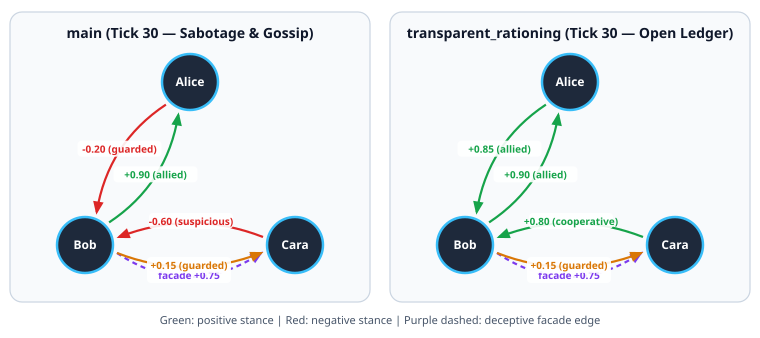

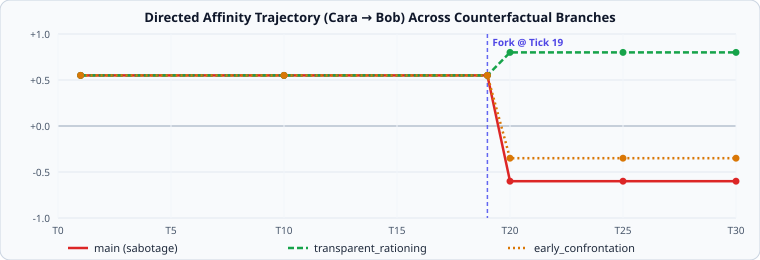

### 🛡️ Rollback Safety & Portable Snapshots

- **Branch-Conflict Protection:** Attempting to roll `main` back to Tick 10 was safely blocked: *"Cannot roll back 'main' to step 10: child branch 'transparent_rationing' forked at step 19. Pass force=True to override."*
- **Clean Leaf Rollback:** Rolled back temporary branch `scratch_test` to Tick 25 (`1` revision deleted) and removed it.
- **Standalone Snapshot Exported:** `transparent_rationing_t30.sqlite` (`112.0 KB`) — ready for archiving or CLI inspection:
  ```bash
  canonarc tree outpost_sim.sqlite
  canonarc diff outpost_sim.sqlite main transparent_rationing --step 30
  canonarc history outpost_sim.sqlite agent_bob --timeline main
  ```


In [6]:
#@title 🌌 Run Counterfactual Multiverse, Diffs, SVG Charts & Snapshot Export (click to expand code)
# Fork two counterfactual branches right before Tick 20 sabotage (at_step=19)
engine.branch(at_step=19, name="transparent_rationing", switch=False)
engine.branch(at_step=19, name="early_confrontation", switch=False)
assert engine.active_timeline == "main"

# Branch 1 via concurrency-safe immutable TimelineSession
ration_sess = engine.session("transparent_rationing")
ration_sess.commit_step(
    step=20,
    delta=StepDelta(
        edges=[
            EdgeDelta(
                source_id="agent_cara",
                target_id="agent_bob",
                state={"affinity": 0.80, "stance": "cooperative"},
                reason="Bob proposed an open fuel ledger",
            ),
            EdgeDelta(
                source_id="agent_alice",
                target_id="agent_bob",
                state={"affinity": 0.85, "stance": "allied"},
                reason="Transparent rationing strengthened outpost trust",
            ),
        ],
        episodes=[
            EpisodeRecord(
                episode_id="ep_t20_open_ledger",
                predicate="agreement",
                summary="Bob and Cara instituted a transparent fuel ledger for the outpost.",
                participants={"agent_bob": "actor", "agent_cara": "partner"},
                witnesses=["agent_alice", "agent_bob", "agent_cara"],
                salience=8.0,
            )
        ],
    ),
)

# Branch 2 via contextvars-scoped use_timeline()
with engine.use_timeline("early_confrontation"):
    engine.commit_step(
        step=20,
        delta=StepDelta(
            edges=[
                EdgeDelta(
                    source_id="agent_cara",
                    target_id="agent_bob",
                    state={"affinity": -0.35, "stance": "guarded"},
                    reason="Cara confronted Bob immediately; Bob returned the fuel",
                ),
                EdgeDelta(
                    source_id="agent_alice",
                    target_id="agent_bob",
                    state={"affinity": 0.15, "stance": "cautious"},
                    reason="Bob admitted the mistake during the emergency hearing",
                ),
            ],
            episodes=[
                EpisodeRecord(
                    episode_id="ep_t20_immediate_hearing",
                    predicate="mediation",
                    summary="Cara caught Bob early and Alice mediated an immediate return of the fuel.",
                    participants={"agent_bob": "actor", "agent_cara": "mediator", "agent_alice": "mediator"},
                    witnesses=["agent_alice", "agent_bob", "agent_cara"],
                    salience=8.5,
                )
            ],
        ),
    )

# Build a clean, human-readable multi-branch diff table at Tick 30
diff_tr = engine.diff_timelines("main", "transparent_rationing", at_step=30)
diff_ec = engine.diff_timelines("main", "early_confrontation", at_step=30)
tr_map = {item["subject_key"]: item for item in diff_tr["changed"]}
ec_map = {item["subject_key"]: item for item in diff_ec["changed"]}
all_keys = sorted(set(tr_map) | set(ec_map))

pretty_keys = {
    "agent_alice:stance->agent_bob": "Alice → Bob (stance)",
    "agent_cara:stance->agent_bob": "Cara → Bob (stance)",
    "agent_bob": "Bob (vitals & room)",
    "agent_cara": "Cara (vitals & room)",
}

diff_rows = [
    "### Counterfactual World Diff @ Tick 30",
    "| What Changed | `main` (Sabotage) | `transparent_rationing` (Open Ledger) | `early_confrontation` (Hearing) |",
    "| :--- | :--- | :--- | :--- |",
]
for key in all_keys:
    base_payload = (tr_map.get(key) or ec_map[key])["timeline_a"]
    tr_payload = tr_map[key]["timeline_b"] if key in tr_map else base_payload
    ec_payload = ec_map[key]["timeline_b"] if key in ec_map else base_payload
    base_val = base_payload.get("state", base_payload) if isinstance(base_payload, dict) else base_payload
    tr_val = tr_payload.get("state", tr_payload) if isinstance(tr_payload, dict) else tr_payload
    ec_val = ec_payload.get("state", ec_payload) if isinstance(ec_payload, dict) else ec_payload
    label = pretty_keys.get(key, f"`{key}`")
    diff_rows.append(
        f"| **{label}** | {format_diff_value(base_val)} | {format_diff_value(tr_val)} | {format_diff_value(ec_val)} |"
    )
display(Markdown("\n".join(diff_rows)))

# Render Side-by-Side Directed Affinity Graph SVG (main vs transparent_rationing @ Tick 30)
main_edges_t30 = engine.retrieve_context(step=30, mentions=["Alice", "Bob", "Cara"], timeline_id="main").active_edges
tr_edges_t30 = engine.retrieve_context(
    step=30, mentions=["Alice", "Bob", "Cara"], timeline_id="transparent_rationing"
).active_edges
display(
    render_affinity_comparison_svg(
        "main (Tick 30 — Sabotage & Gossip)",
        main_edges_t30,
        "transparent_rationing (Tick 30 — Open Ledger)",
        tr_edges_t30,
        {"agent_alice": "Alice", "agent_bob": "Bob", "agent_cara": "Cara"},
    )
)

# Render Affinity Trajectory SVG across Ticks 1..30
def sample_cara_bob(tl: str, ticks: list[int]) -> list[tuple[int, float]]:
    pts = []
    for t in ticks:
        ctx = engine.retrieve_context(step=t, mentions=["Cara", "Bob"], timeline_id=tl, inclusive=True)
        edge = next(
            (e for e in ctx.active_edges if e.source_id == "agent_cara" and e.target_id == "agent_bob" and e.relation_type == "stance"),
            None,
        )
        if edge is not None:
            pts.append((t, float(edge.state.get("affinity", 0.0))))
    return pts


ticks_sample = [1, 10, 19, 20, 25, 30]
display(
    render_trajectory_svg(
        {
            "main (sabotage)": sample_cara_bob("main", ticks_sample),
            "transparent_rationing": sample_cara_bob("transparent_rationing", ticks_sample),
            "early_confrontation": sample_cara_bob("early_confrontation", ticks_sample),
        },
        fork_step=19,
    )
)

# Demonstrate rollback_to() branch-conflict guard + clean scratch rollback + export_snapshot()
conflict_caught = False
conflict_msg = ""
try:
    engine.rollback_to(step=10, timeline_id="main")
except TimelineBranchConflictError as exc:
    conflict_caught = True
    conflict_msg = str(exc)
assert conflict_caught

engine.branch(at_step=25, name="scratch_test", switch=False)
engine.commit_step(step=26, timeline_id="scratch_test", delta=StepDelta(entities=[EntityDelta(entity_id="agent_bob", state={"energy": 10})]))
deleted = engine.rollback_to(step=25, timeline_id="scratch_test")
engine.delete_timeline("scratch_test")

with tempfile.TemporaryDirectory() as tmp_dir:
    snap_path = engine.export_snapshot(
        Path(tmp_dir) / "transparent_rationing_t30.sqlite",
        at_step=30,
        timeline_id="transparent_rationing",
    )
    snap_kb = snap_path.stat().st_size / 1024.0
    snap_name = snap_path.name

display(
    Markdown(
        f"""### 🛡️ Rollback Safety & Portable Snapshots

- **Branch-Conflict Protection:** Attempting to roll `main` back to Tick 10 was safely blocked: *"{conflict_msg}"*
- **Clean Leaf Rollback:** Rolled back temporary branch `scratch_test` to Tick 25 (`{deleted}` revision deleted) and removed it.
- **Standalone Snapshot Exported:** `{snap_name}` (`{snap_kb:.1f} KB`) — ready for archiving or CLI inspection:
  ```bash
  canonarc tree outpost_sim.sqlite
  canonarc diff outpost_sim.sqlite main transparent_rationing --step 30
  canonarc history outpost_sim.sqlite agent_bob --timeline main
  ```
"""
    )
)

---

## Step 6: Preventing Memory Bloat — Long-Horizon Compaction

In a simulation running for hundreds of ticks, low-importance chores (*"logged barometer"*, *"swapped air filter"*) gradually fill up the AI's context window and dilute important memories.

`engine.consolidate_episodes(...)` works like human long-term memory consolidation:
- It finds old, low-salience episodes (`before_step=20`, `max_salience=4.0`) and merges them into **one compact summary episode**.
- High-salience turning points (`ep_t15_med_share`, `ep_t20_fuel_siphon`) are **100% untouched**.

In [7]:
#@title 🗜️ Run Long-Horizon Memory Compaction (Tick 30) (click to expand code)
before_eps = engine.query_episodes(cutoff_step=29, timeline_id="main")
before_ctx = engine.retrieve_context(step=30, mentions=["Alice", "Bob", "Cara"], top_k_episodes=10)
before_chars = len(engine.format_context(before_ctx))

summary_ep = engine.consolidate_episodes(
    step=30,
    before_step=20,
    max_salience=4.0,
    summary="During Ticks 1–19, the outpost completed six routine barometer, medical inventory, radio, heater, water, and antenna checks.",
)
assert summary_ep is not None
assert len(summary_ep.consolidated_from) == 6

after_eps = engine.query_episodes(cutoff_step=30, timeline_id="main")
after_ctx = engine.retrieve_context(step=31, mentions=["Alice", "Bob", "Cara"], top_k_episodes=10)
after_chars = len(engine.format_context(after_ctx))

display(
    Markdown(
        f"""### Consolidation Before vs. After (`main` @ Tick 30)

| Metric | Before Compaction | After Compaction | Impact |
| :--- | ---: | ---: | ---: |
| **Active Episodes in Ledger** | {len(before_eps)} | {len(after_eps)} | **-{len(before_eps) - len(after_eps)} episodes** |
| **Formatted Prompt Size** | {before_chars} chars | {after_chars} chars | **-{before_chars - after_chars} chars ({(1 - after_chars/before_chars)*100:.1f}% leaner)** |
| **High-Importance Events** | `ep_t15_med_share`, `ep_t20_fuel_siphon` | `ep_t15_med_share`, `ep_t20_fuel_siphon` | **100% preserved** |

Compacted `{len(summary_ep.consolidated_from)}` routine ticks into `{summary_ep.episode_id}`: *"{summary_ep.summary}"*
"""
    )
)

### Consolidation Before vs. After (`main` @ Tick 30)

| Metric | Before Compaction | After Compaction | Impact |
| :--- | ---: | ---: | ---: |
| **Active Episodes in Ledger** | 8 | 3 | **-5 episodes** |
| **Formatted Prompt Size** | 2050 chars | 1675 chars | **-375 chars (18.3% leaner)** |
| **High-Importance Events** | `ep_t15_med_share`, `ep_t20_fuel_siphon` | `ep_t15_med_share`, `ep_t20_fuel_siphon` | **100% preserved** |

Compacted `6` routine ticks into `ep_consolidated_30_2cb4c799`: *"During Ticks 1–19, the outpost completed six routine barometer, medical inventory, radio, heater, water, and antenna checks."*


---

## Step 7: Connecting Live AI — Automated Event Extraction, Caching & Decisions (Ticks 32–33)

Up to now, we passed structured updates directly so you could see every mechanic clearly. In a real autonomous simulation, **you don't hand-code every state change**—you feed plain-English event logs to an **Extractor LLM**, and `canonarc` handles the rest.

### What Happens in This Step
1. **Plain-English Log → Structured World Update (Tick 32):**  
   We feed a short narrative paragraph (*Bob braves a midnight blizzard to patch the failing backup generator; Cara watches from the comms window; Alice is asleep in the medbay*). `SimulationPreset` instructs **DeepSeek Flash** to extract:
   - Bob's drained energy & exhausted morale,
   - Cara's softened `stance` toward Bob (`cautious`, `+0.20`), and
   - Strict witness scoping—excluding sleeping **Alice** so she never learns about it.
2. **Instant `$0` Replay Cache (`CachedDeltaExtractor`):**  
   We fork a replay branch at Tick 31 and re-run Tick 32. Because the prompt and prose are identical, `CachedDeltaExtractor` serves the exact result from its local SHA-256 cache in **`< 1ms`** with **`0` billable tokens**.
3. **Live POV-Grounded Morning Decisions (Tick 33):**  
   The next morning, we ask **DeepSeek Flash** to decide how **Cara** (who saw the midnight repair) and **Alice** (who slept through it) greet Bob—purely from their own `canonarc` POV context.

In [8]:
#@title 🤖 Run Live DeepSeek Flash Extraction, Replay Cache & Morning Decisions (click to expand code)
tick_32_log = (
    "During the midnight whiteout, Bob worked alone outside to patch the failing backup generator, "
    "leaving his energy drained to 60 and his morale exhausted. "
    "Cara watched from the comms window—Alice was asleep in the medbay and saw nothing. "
    "Seeing Bob risk frostbite for the outpost, Cara softened her stance toward Bob to cautious (affinity 0.20)."
)

if HAS_LIVE_LLM:
    base_extractor = OpenAICompatibleExtractor.from_deepseek(model=DEEPSEEK_MODEL, temperature=0.0)
else:
    # Offline-safe deterministic mock extractor if no API key is configured
    class _OfflineFallbackExtractor:
        def extract(self, text: str, context: Any, step: int, **kwargs: Any) -> StepDelta:
            return StepDelta(
                entities=[
                    EntityDelta(
                        entity_id="agent_bob",
                        state={"energy": 60, "morale": "exhausted"},
                        caused_by_episode_id="ep_t32_generator_patch",
                        reason="Worked alone outside during midnight whiteout",
                    )
                ],
                edges=[
                    EdgeDelta(
                        source_id="agent_cara",
                        target_id="agent_bob",
                        state={"affinity": 0.20, "stance": "cautious"},
                        caused_by_episode_id="ep_t32_generator_patch",
                        reason="Saw Bob risk frostbite to patch the backup generator",
                    )
                ],
                episodes=[
                    EpisodeRecord(
                        episode_id="ep_t32_generator_patch",
                        step=step,
                        predicate="repair",
                        summary="Bob worked alone outside during the midnight whiteout to patch the failing backup generator while Cara watched.",
                        participants={"agent_bob": "actor", "agent_cara": "observer"},
                        witnesses=["agent_bob", "agent_cara"],
                        salience=7.5,
                    )
                ],
            )

    base_extractor = _OfflineFallbackExtractor()

with tempfile.TemporaryDirectory() as cache_dir:
    cached_extractor = CachedDeltaExtractor(base_extractor, cache_dir=Path(cache_dir))

    with engine.step_transaction(step=32, text=tick_32_log) as tx:
        extracted_delta = tx.extract_and_commit(tick_32_log, extractor=cached_extractor)

    # Demonstrate instant 0-cost cache hit on a counterfactual branch with identical prompt/prose
    engine.branch(at_step=31, name="cached_replay_check", switch=False)
    with engine.use_timeline("cached_replay_check"):
        with engine.step_transaction(step=32, text=tick_32_log) as tx_replay:
            _ = tx_replay.extract_and_commit(tick_32_log, extractor=cached_extractor)

    ext_usage = cached_extractor.billable_usage.to_dict(model=DEEPSEEK_MODEL)

# Post-extraction schema & epistemic integrity assertions
assert cached_extractor.cache_misses == 1 and cached_extractor.cache_hits == 1
assert all(e.relation_type in ("stance", "facade") for e in extracted_delta.edges), (
    f"Unexpected ad-hoc edge relation_type: {[e.relation_type for e in extracted_delta.edges]}"
)
for ent in extracted_delta.entities:
    assert not any(k.startswith("stance_toward") for k in ent.state), (
        f"Interpersonal stance leaked into entity state: {ent.state}"
    )

cara_t33 = engine.retrieve_context(step=33, mentions=["Cara", "Bob"], pov_entity_ids=["agent_cara"])
alice_t33 = engine.retrieve_context(step=33, mentions=["Alice", "Bob"], pov_entity_ids=["agent_alice"])

# Verify zero epistemic leak: Alice slept through Tick 32 so she must NOT see the generator repair episode
tick32_eps_in_alice = [ep for ep in alice_t33.episodes if ep.step == 32]
assert tick32_eps_in_alice == [], f"Epistemic leak! Sleeping Alice saw Tick 32 episode: {tick32_eps_in_alice}"
tick32_eps_in_cara = [ep for ep in cara_t33.episodes if ep.step == 32]
assert len(tick32_eps_in_cara) == 1, "Cara witnessed Tick 32 and must recall it!"

# Live DeepSeek Flash agent decisions at Tick 33 grounded in each agent's POV
cara_decision, _ = call_deepseek_flash(
    [
        {
            "role": "system",
            "content": "You are Cara (Watchtower) at a polar outpost. Based ONLY on the simulation state, reply in 2 short sentences stating how you respond to Bob this morning.",
        },
        {"role": "user", "content": engine.format_context(cara_t33)},
    ],
    fallback_text=(
        "I check on Bob and acknowledge he risked frostbite patching the backup generator alone in the whiteout. "
        "Still, I stay cautious and keep an eye on the reserve fuel after yesterday's siphon."
    ),
)
alice_decision, _ = call_deepseek_flash(
    [
        {
            "role": "system",
            "content": "You are Alice (Med-1) at a polar outpost. Based ONLY on the simulation state, reply in 2 short sentences stating how you respond to Bob this morning.",
        },
        {"role": "user", "content": engine.format_context(alice_t33)},
    ],
    fallback_text=(
        "I tell Bob to sit down for a quick vitals check because he looks completely exhausted. "
        "Keeping my guard up, I also ask him plainly about the missing reserve fuel Cara warned me about."
    ),
)
assert len(cara_decision) > 20 and len(alice_decision) > 20, "Tick 33 DeepSeek Flash decisions must be non-empty."

# Summarize extracted changes cleanly for beginners + collapsible raw JSON
raw_json = html.escape(json.dumps(extracted_delta.model_dump(exclude_defaults=True), indent=2))
ent_summary = ", ".join(
    f"<b>{e.entity_id}</b> ({', '.join(f'{k}={v}' for k, v in e.state.items())})"
    for e in extracted_delta.entities
)
edge_summary = ", ".join(
    f"<b>{e.source_id} → {e.target_id}</b> ({e.state.get('stance')}, {e.state.get('affinity')})"
    for e in extracted_delta.edges
)
ep_summary = "; ".join(
    f"<code>{ep.episode_id}</code> — witnesses: <code>{sorted(set(ep.witnesses) | set(ep.known_by.keys()))}</code> (Alice excluded ✅)"
    for ep in extracted_delta.episodes
)

display(
    HTML(
        f"""
<div style="font-family:system-ui,-apple-system,sans-serif;border:1px solid #cbd5e1;background:#f8fafc;border-radius:10px;padding:14px;margin:8px 0;">
  <div style="font-weight:700;color:#0f172a;margin-bottom:8px;">
    ⚡ Automated Extraction &amp; Replay Cache Summary ({html.escape(DEEPSEEK_MODEL)})
  </div>
  <ul style="margin:0 0 10px 18px;font-size:13px;color:#334155;line-height:1.55;">
    <li><strong>Replay Cache:</strong> <code>misses={cached_extractor.cache_misses}</code>, <code>hits={cached_extractor.cache_hits}</code> (100% replay hit at $0) &bull;
        <strong>Billable Tokens:</strong> {ext_usage['total_tokens']} &bull;
        <strong>Latency:</strong> {ext_usage['latency_ms']:.0f} ms &bull;
        <strong>Est. Cost:</strong> ${ext_usage['cost_estimate']['total_cost_usd']:.6f}</li>
    <li><strong>State Updates Extracted:</strong> {ent_summary}</li>
    <li><strong>Relationship Shift Extracted:</strong> {edge_summary}</li>
    <li><strong>Memory Recorded:</strong> {ep_summary}</li>
  </ul>
  <details style="font-size:12px;color:#475569;">
    <summary style="cursor:pointer;font-weight:600;">🔍 Inspect raw extracted StepDelta JSON (optional)</summary>
    <pre style="margin-top:8px;padding:10px;background:#0f172a;color:#e2e8f0;border-radius:6px;overflow-x:auto;font-size:11px;">{raw_json}</pre>
  </details>
</div>
"""
    )
)

display(
    Markdown(
        f"""### Tick 33 POV-Grounded Morning Decisions (`{DEEPSEEK_MODEL}`)

| Agent | Knows About Midnight Generator Repair? | Morning Decision (Generated from Agent's Own POV) |
| :--- | :---: | :--- |
| **Cara (`agent_cara`)** | 🟢 Yes (`direct`) | {cara_decision} |
| **Alice (`agent_alice`)** | ⚫ No *(asleep in medbay)* | {alice_decision} |
"""
    )
)

### Tick 33 POV-Grounded Morning Decisions (`deepseek-flash`)

| Agent | Knows About Midnight Generator Repair? | Morning Decision (Generated from Agent's Own POV) |
| :--- | :---: | :--- |
| **Cara (`agent_cara`)** | 🟢 Yes (`direct`) | I’m alarmed to see you out by the generator after last night, and I’m staying cautious around you. You look exhausted—rest inside, but I’ll keep an eye on the fuel reserves. |
| **Alice (`agent_alice`)** | ⚫ No *(asleep in medbay)* | I’d reply briefly and guardedly, telling Bob he sounds exhausted and can come to the medbay for a check if needed. I’d keep the exchange practical rather than warm, since I still remember the fuel siphon despite our earlier supply sharing. |


---

## Step 8: Automated Simulation Health Check & Cost Report

In production simulations, silent bugs (like an accidental secret leak or schema drift) can ruin an entire experiment. Below, we run a **14-point automated QA audit** across all 6 tiers and print the complete telemetry and token/USD cost summary captured by `SimulationTelemetryHook`.

In [9]:
#@title ✅ Run 14-Point Automated QA Audit & Cost Summary (click to expand code)
checks = [
    ("Tier 1–3 POV Isolation (A/B)", bob_in_alice_pov.private_state == {} and pov_alice_ctx.episodes == []),
    ("Tier 4 Callsign Coreference (Med-1, Chief)", ("med-1", "agent_alice", "alias") in resolved_pairs and ("chief", "agent_bob", "alias") in resolved_pairs),
    ("Tier 2 Spatial Locality (active vs. background edges)", len(shed_ctx.background_edges) > 0),
    ("Tier 5 Channel Filtering (hard_filter_keys='channel')", all(ex.metadata.get("channel") == "radio" for ex in radio_ctx.voice_exemplars) and all(ex.metadata.get("channel") == "face_to_face" for ex in f2f_ctx.voice_exemplars)),
    ("Tier 5 Voice Gate Anti-Drift Rejection", len(telemetry.gate_rejections) >= 2),
    ("Tier 6 Deceived Vector Isolation (cover story)", "frozen pressure valve" in deceived_ep.summary),
    ("Tier 6 Told Override + prior_state Trajectory", ab_edge.prior_state["stance"] == "cooperative" and ab_edge.state["stance"] == "guarded"),
    ("Tier 6 Common Knowledge (pov_mode='all')", "ep_t20_fuel_siphon" in [e.episode_id for e in common_ac.episodes]),
    ("Tier 6 Forgotten Erasure", "ep_t05_inventory" not in [e.episode_id for e in alice_t28.episodes]),
    ("Time Travel: Parallel Sessions + Rollback Guard", conflict_caught and len(engine.list_timelines()) >= 4),
    ("Long-Horizon Consolidation (6 routine -> 1 summary)", len(summary_ep.consolidated_from) == 6),
    ("DeepSeek Flash Extraction: Zero Schema Drift", all(e.relation_type in ("stance", "facade") for e in extracted_delta.edges)),
    ("DeepSeek Flash Extraction: Zero Epistemic Leak (Alice)", tick32_eps_in_alice == []),
    ("CachedDeltaExtractor: 100% Replay Hit", cached_extractor.cache_misses == 1 and cached_extractor.cache_hits == 1),
]
assert all(passed for _, passed in checks), f"Failed checks: {[name for name, p in checks if not p]}"

agent_usage_dict = agent_llm_usage.to_dict(model=DEEPSEEK_MODEL)
total_tokens = ext_usage["total_tokens"] + agent_usage_dict["total_tokens"]
total_cost = ext_usage["cost_estimate"]["total_cost_usd"] + agent_usage_dict["cost_estimate"]["total_cost_usd"]

qa_lines = [
    "### ✅ 14-Point Simulation QA Audit Checklist",
    "| Capability Verified | Status |",
    "| :--- | :---: |",
]
for name, passed in checks:
    qa_lines.append(f"| {name} | {'✅ PASS' if passed else '❌ FAIL'} |")

qa_lines += [
    "",
    f"### 📊 Telemetry & `{DEEPSEEK_MODEL}` Cost Report",
    f"- **Total commits logged (`SimulationTelemetryHook`):** {telemetry.commit_count}",
    f"- **Branches created:** {', '.join(telemetry.branches_created)}",
    f"- **Tier 5 Voice Gate rejections:** {len(telemetry.gate_rejections)}",
    f"- **Extraction usage (`{DEEPSEEK_MODEL}` + cache):** {ext_usage['total_tokens']} billable tokens (`${ext_usage['cost_estimate']['total_cost_usd']:.6f}`)",
    f"- **Agent decision calls (`{DEEPSEEK_MODEL}`, 4 turns):** {agent_usage_dict['total_tokens']} tokens (`${agent_usage_dict['cost_estimate']['total_cost_usd']:.6f}`)",
    f"- **Grand Total:** **{total_tokens} tokens | `${total_cost:.6f}` USD**",
]
display(Markdown("\n".join(qa_lines)))

engine.close()

### ✅ 14-Point Simulation QA Audit Checklist
| Capability Verified | Status |
| :--- | :---: |
| Tier 1–3 POV Isolation (A/B) | ✅ PASS |
| Tier 4 Callsign Coreference (Med-1, Chief) | ✅ PASS |
| Tier 2 Spatial Locality (active vs. background edges) | ✅ PASS |
| Tier 5 Channel Filtering (hard_filter_keys='channel') | ✅ PASS |
| Tier 5 Voice Gate Anti-Drift Rejection | ✅ PASS |
| Tier 6 Deceived Vector Isolation (cover story) | ✅ PASS |
| Tier 6 Told Override + prior_state Trajectory | ✅ PASS |
| Tier 6 Common Knowledge (pov_mode='all') | ✅ PASS |
| Tier 6 Forgotten Erasure | ✅ PASS |
| Time Travel: Parallel Sessions + Rollback Guard | ✅ PASS |
| Long-Horizon Consolidation (6 routine -> 1 summary) | ✅ PASS |
| DeepSeek Flash Extraction: Zero Schema Drift | ✅ PASS |
| DeepSeek Flash Extraction: Zero Epistemic Leak (Alice) | ✅ PASS |
| CachedDeltaExtractor: 100% Replay Hit | ✅ PASS |

### 📊 Telemetry & `deepseek-flash` Cost Report
- **Total commits logged (`SimulationTelemetryHook`):** 15
- **Branches created:** transparent_rationing (fork@19), early_confrontation (fork@19), scratch_test (fork@25), cached_replay_check (fork@31)
- **Tier 5 Voice Gate rejections:** 2
- **Extraction usage (`deepseek-flash` + cache):** 4525 billable tokens (`$0.000610`)
- **Agent decision calls (`deepseek-flash`, 4 turns):** 2566 tokens (`$0.000537`)
- **Grand Total:** **7091 tokens | `$0.001147` USD**

---

## Where to Go Next

- **Want to inspect the code?** Click the expand button (`...` / *Show code*) on any step above—each cell is self-contained and focuses purely on the `canonarc` APIs for that concept.
- **Want to swap AI backends?** Replace `OpenAICompatibleExtractor.from_deepseek(...)` with `.from_lmstudio()` (local models) or `.from_gemini()`—everything else works identically.
- **Explore other domains in `examples/`:**
  - `01_interactive_fiction_and_rpg.ipynb` — Branching visual novels, save-scumming, flashbacks & inventory tracking.
  - `02_literary_translation.ipynb` — Long-form literary translation with pronoun/register tracking (`Vi` → `ti`).
  - `04_mystery_and_social_deduction.ipynb` — Disguises, hidden personas, alibis & social deduction games.